# Setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
from copy import deepcopy
import multiprocessing as mp
import logging
import random

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np
from dotenv import load_dotenv

from halcyon.Simulators.SimulationResult import SimulationResult
from halcyon.results.manipulate_results_df import (create_tidy_df_from_mlflow_runs, 
                                                   split_df_into_single_and_double_ko,
                                                   add_model_name_to_df,
                                                   df_with_ground_truth_as_kind_of_model)

from halcyon.results.plot_from_df import plot_model_plots, plot_per_gene_mse_heatmap, rotate_x_tick_labels, wrap_titles

from halcyon.results import DfColumnNames

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

# Load from MLFlow

## Best ML runs

In [2]:
runs_to_download = []
filter_string = "params.lambda_l1 = '0.0' and params.hidden_size = '10' and params.nr_layers = '2' and params.synthesis_only_positive = 'False'"
runs_to_download.extend(mlflow.search_runs(filter_string=filter_string, experiment_ids=['4'], output_format='list'))

In [3]:
len(runs_to_download)

3

## Hybrid and MM runs

In [4]:
hybrid_and_mm_runs = mlflow.search_runs(filter_string="attributes.status = 'FINISHED'", experiment_ids=['6'], output_format='list')
runs_to_download.extend(hybrid_and_mm_runs)
print(len(runs_to_download))

37


In [5]:
raw_predictions_df = create_tidy_df_from_mlflow_runs(runs_to_download)

2026-04-13 09:46:55,352 - INFO - Downloading artifacts for run e51261c9ab8644edaef773a45d9d8551


2026-04-13 09:47:00,618 - INFO - Downloading artifacts for run 0d56cdfb0da342c5abfc20196377c1fd


2026-04-13 09:47:01,954 - INFO - Downloading artifacts for run 6a3375f5c070446f996b2719f487da25


2026-04-13 09:47:04,018 - INFO - Downloading artifacts for run 1914c2fd8fd949fea18c15a6c7ed7073


2026-04-13 09:47:05,152 - INFO - Downloading artifacts for run 973239ca0ebb4fd182b2c97f6f17b195


...

2026-04-13 09:47:34,115 - INFO - Downloading artifacts for run 179aaca376b248a7a102499c150dc642


2026-04-13 09:47:35,014 - INFO - Downloading artifacts for run 0b0fa46aa0ec43d2a18e78ec8bfe386e


2026-04-13 09:47:35,915 - INFO - Downloading artifacts for run 8736d8075cf34be390d737bf3740c151


2026-04-13 09:47:36,816 - INFO - Downloading artifacts for run 5eab6075d6144f08bd03d7b44aea6a80


2026-04-13 09:47:37,722 - INFO - Downloading artifacts for run d4adee2c979c4452b9e970152af0b3f4


In [6]:
raw_predictions_df.head()

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id
0,Node_0,0.0,0.417963,0.417963,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,e56b1774f68349209f3b7e672158fa01
1,Node_1,0.0,0.393894,0.393894,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,e56b1774f68349209f3b7e672158fa01
2,Node_2,0.0,0.071135,0.071135,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,e56b1774f68349209f3b7e672158fa01
3,Node_3,0.0,0.455552,0.455552,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,e56b1774f68349209f3b7e672158fa01
4,Node_4,0.0,0.562109,0.562109,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,e56b1774f68349209f3b7e672158fa01


In [7]:
model_name_records = []
for run_id in raw_predictions_df['run_id'].unique():
    model_name_records.append({
        'run_id': run_id,
        'model_name': mlflow.get_run(run_id).data.tags['mlflow.runName']})
model_name_df = pd.DataFrame(model_name_records)
model_name_df

,run_id,model_name
0,e51261c9ab8644edaef773a45d9d8551,MLP
1,0d56cdfb0da342c5abfc20196377c1fd,MLP
2,6a3375f5c070446f996b2719f487da25,MLP
3,1914c2fd8fd949fea18c15a6c7ed7073,HybridModel
4,973239ca0ebb4fd182b2c97f6f17b195,HybridModel
5,3df0ab220d77426b905d07f829853d42,HybridModel
6,23512073edb14bd5964fa982890d6884,HybridModel
7,e269588c06084f7cbe2ccf44f15ca361,HybridModel
8,013b5675eabe4b43a5355fce64791aaa,HybridModel
9,9468aeb47485434286232c3cae03e54a,HybridModel


In [8]:
raw_predictions_df = pd.merge(raw_predictions_df, model_name_df, on='run_id')

Add number of genes

In [9]:
records = []
for run_id in raw_predictions_df['parent_run_id'].unique():
    records.append({
        'parent_run_id': run_id,
        'nr_genes': mlflow.get_run(run_id).data.params['nr_genes']
    })
nr_genes_df = pd.DataFrame(records)
nr_genes_df.head()

,parent_run_id,nr_genes
0,e56b1774f68349209f3b7e672158fa01,100
1,19ba6fc0e8094a66a68f2f67cdca2162,50
2,d660c1d337c34d98a349605d9b4d5b47,20


Add noiseless expression values

In [10]:
records = []
for run_id in raw_predictions_df['parent_run_id'].unique():
    ml_flow_download_path = mlflow.artifacts.download_artifacts(
        run_id=run_id, artifact_path="dataset"
    )
    sim_output = SimulationResult.load_from_pkl(
        Path(ml_flow_download_path) / "simulation_result.pkl"
    )
    sim_output.noiseless_for_testing = True
    long_form_simulation = sim_output.to_long_form_df()
    long_form_simulation[DfColumnNames.RUN_ID_COL] = run_id
    records.append(long_form_simulation)
long_form_simulation = pd.concat(records, ignore_index=True)

2026-04-13 09:47:51,977 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-13 09:47:51,984 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-13 09:47:51,999 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-13 09:47:52,055 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-13 09:47:52,071 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-13 09:47:52,078 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-13 09:47:52,091 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-13 09:47:52,107 - WARNING - Connection p

2026-04-13 09:47:58,648 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-13 09:47:58,681 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-13 09:47:58,693 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-13 09:47:58,707 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-13 09:47:58,734 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-13 09:47:58,739 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-13 09:47:58,776 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-13 09:47:58,781 - WARNING - Connection p

2026-04-13 09:48:03,648 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-13 09:48:03,670 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-13 09:48:03,675 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-13 09:48:03,689 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-13 09:48:03,705 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-13 09:48:03,724 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-13 09:48:03,740 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-04-13 09:48:03,767 - WARNING - Connection p

In [11]:
nr_genes_df.head()

,parent_run_id,nr_genes
0,e56b1774f68349209f3b7e672158fa01,100
1,19ba6fc0e8094a66a68f2f67cdca2162,50
2,d660c1d337c34d98a349605d9b4d5b47,20


In [12]:
raw_predictions_df.head()

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id,model_name
0,Node_0,0.0,0.417963,0.417963,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,e56b1774f68349209f3b7e672158fa01,MLP
1,Node_1,0.0,0.393894,0.393894,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,e56b1774f68349209f3b7e672158fa01,MLP
2,Node_2,0.0,0.071135,0.071135,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,e56b1774f68349209f3b7e672158fa01,MLP
3,Node_3,0.0,0.455552,0.455552,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,e56b1774f68349209f3b7e672158fa01,MLP
4,Node_4,0.0,0.562109,0.562109,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,e56b1774f68349209f3b7e672158fa01,MLP


In [13]:
long_form_simulation.head()

,gene,time,ground_truth,condition,run_id
0,Node_0,0.0,0.638225,KO: Node_0. Env: None,e56b1774f68349209f3b7e672158fa01
1,Node_1,0.0,0.221312,KO: Node_0. Env: None,e56b1774f68349209f3b7e672158fa01
2,Node_2,0.0,0.131817,KO: Node_0. Env: None,e56b1774f68349209f3b7e672158fa01
3,Node_3,0.0,0.726280,KO: Node_0. Env: None,e56b1774f68349209f3b7e672158fa01
4,Node_4,0.0,0.382572,KO: Node_0. Env: None,e56b1774f68349209f3b7e672158fa01


Merging

In [14]:
outcome = pd.merge(
    raw_predictions_df, 
    long_form_simulation, 
    left_on=['parent_run_id', 'gene', 'time', 'condition'], 
    right_on=['run_id', 'gene', 'time', 'condition'], 
    validate='m:1',
    suffixes=['_from_pred_df', '_from_simulation'])

outcome = pd.merge(outcome, nr_genes_df, on='parent_run_id')

In [15]:
outcome.head()

,gene,time,predicted_expression,ground_truth_from_pred_df,condition,run_id_from_pred_df,parent_run_id,model_name,ground_truth_from_simulation,run_id_from_simulation,nr_genes
0,Node_0,0.0,0.417963,0.417963,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,e56b1774f68349209f3b7e672158fa01,MLP,0.638225,e56b1774f68349209f3b7e672158fa01,100
1,Node_1,0.0,0.393894,0.393894,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,e56b1774f68349209f3b7e672158fa01,MLP,0.221312,e56b1774f68349209f3b7e672158fa01,100
2,Node_2,0.0,0.071135,0.071135,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,e56b1774f68349209f3b7e672158fa01,MLP,0.131817,e56b1774f68349209f3b7e672158fa01,100
3,Node_3,0.0,0.455552,0.455552,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,e56b1774f68349209f3b7e672158fa01,MLP,0.726280,e56b1774f68349209f3b7e672158fa01,100
4,Node_4,0.0,0.562109,0.562109,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,e56b1774f68349209f3b7e672158fa01,MLP,0.382572,e56b1774f68349209f3b7e672158fa01,100


In [16]:
np.isclose(outcome['ground_truth_from_pred_df'], outcome['ground_truth_from_simulation']).all()

np.False_

<Axes: xlabel='ground_truth_from_simulation', ylabel='ground_truth_from_pred_df'>

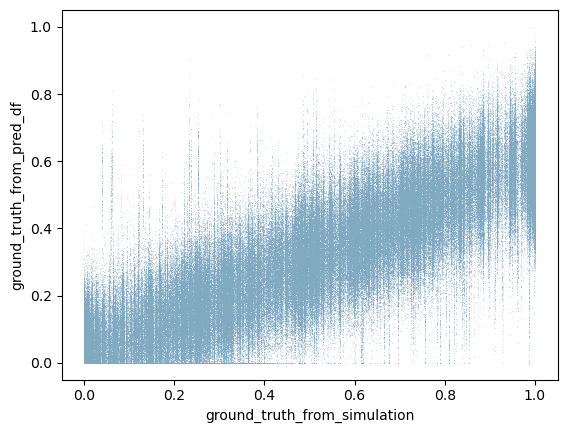

In [17]:
sns.scatterplot(data=outcome, x='ground_truth_from_simulation', y='ground_truth_from_pred_df', s=.1, marker='.', alpha=.5)

Keep only the relevant columns in the outcome df

In [18]:
outcome

,gene,time,predicted_expression,ground_truth_from_pred_df,condition,run_id_from_pred_df,parent_run_id,model_name,ground_truth_from_simulation,run_id_from_simulation,nr_genes
0,Node_0,0.0,0.417963,0.417963,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,e56b1774f68349209f3b7e672158fa01,MLP,0.638225,e56b1774f68349209f3b7e672158fa01,100
1,Node_1,0.0,0.393894,0.393894,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,e56b1774f68349209f3b7e672158fa01,MLP,0.221312,e56b1774f68349209f3b7e672158fa01,100
2,Node_2,0.0,0.071135,0.071135,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,e56b1774f68349209f3b7e672158fa01,MLP,0.131817,e56b1774f68349209f3b7e672158fa01,100
3,Node_3,0.0,0.455552,0.455552,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,e56b1774f68349209f3b7e672158fa01,MLP,0.726280,e56b1774f68349209f3b7e672158fa01,100
4,Node_4,0.0,0.562109,0.562109,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,e56b1774f68349209f3b7e672158fa01,MLP,0.382572,e56b1774f68349209f3b7e672158fa01,100
...,...,...,...,...,...,...,...,...,...,...,...
5384227,Node_44,1.0,0.074938,0.000000,"KO: Node_1, Node_15. Env: None",d4adee2c979c4452b9e970152af0b3f4,e56b1774f68349209f3b7e672158fa01,PyTorchODE,0.074938,e56b1774f68349209f3b7e672158fa01,100
5384228,Node_60,1.0,0.520854,0.394373,"KO: Node_1, Node_15. Env: None",d4adee2c979c4452b9e970152af0b3f4,e56b1774f68349209f3b7e672158fa01,PyTorchODE,0.520854,e56b1774f68349209f3b7e672158fa01,100
5384229,Node_70,1.0,0.356031,0.162039,"KO: Node_1, Node_15. Env: None",d4adee2c979c4452b9e970152af0b3f4,e56b1774f68349209f3b7e672158fa01,PyTorchODE,0.485790,e56b1774f68349209f3b7e672158fa01,100
5384230,Node_82,1.0,0.549414,0.228576,"KO: Node_1, Node_15. Env: None",d4adee2c979c4452b9e970152af0b3f4,e56b1774f68349209f3b7e672158fa01,PyTorchODE,0.549414,e56b1774f68349209f3b7e672158fa01,100


In [19]:

outcome = outcome[['gene', 'time', 'predicted_expression', 
       'condition', 'run_id_from_pred_df', 'model_name',
       'ground_truth_from_simulation', 'nr_genes']]

outcome = outcome.rename(columns={"run_id_from_pred_df": "run_id", "ground_truth_from_simulation": "noiseless_ground_truth"})

outcome

,gene,time,predicted_expression,condition,run_id,model_name,noiseless_ground_truth,nr_genes
0,Node_0,0.0,0.417963,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,MLP,0.638225,100
1,Node_1,0.0,0.393894,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,MLP,0.221312,100
2,Node_2,0.0,0.071135,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,MLP,0.131817,100
3,Node_3,0.0,0.455552,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,MLP,0.726280,100
4,Node_4,0.0,0.562109,KO: Node_52. Env: None,e51261c9ab8644edaef773a45d9d8551,MLP,0.382572,100
...,...,...,...,...,...,...,...,...
5384227,Node_44,1.0,0.074938,"KO: Node_1, Node_15. Env: None",d4adee2c979c4452b9e970152af0b3f4,PyTorchODE,0.074938,100
5384228,Node_60,1.0,0.520854,"KO: Node_1, Node_15. Env: None",d4adee2c979c4452b9e970152af0b3f4,PyTorchODE,0.520854,100
5384229,Node_70,1.0,0.356031,"KO: Node_1, Node_15. Env: None",d4adee2c979c4452b9e970152af0b3f4,PyTorchODE,0.485790,100
5384230,Node_82,1.0,0.549414,"KO: Node_1, Node_15. Env: None",d4adee2c979c4452b9e970152af0b3f4,PyTorchODE,0.549414,100


In [20]:
outcome.columns

Index(['gene', 'time', 'predicted_expression', 'condition', 'run_id',
       'model_name', 'noiseless_ground_truth', 'nr_genes'],
      dtype='object')

In [21]:
single_ko_df, double_ko_df = split_df_into_single_and_double_ko(outcome)

In [22]:
double_ko_df.head()

,gene,time,predicted_expression,condition,run_id,model_name,noiseless_ground_truth,nr_genes
157500,Node_0,0.0,0.276281,"KO: Node_15, Node_38. Env: None",e51261c9ab8644edaef773a45d9d8551,MLP,0.639008,100
157501,Node_1,0.0,0.032802,"KO: Node_15, Node_38. Env: None",e51261c9ab8644edaef773a45d9d8551,MLP,0.387136,100
157502,Node_2,0.0,0.165385,"KO: Node_15, Node_38. Env: None",e51261c9ab8644edaef773a45d9d8551,MLP,0.438463,100
157503,Node_3,0.0,0.444972,"KO: Node_15, Node_38. Env: None",e51261c9ab8644edaef773a45d9d8551,MLP,0.741222,100
157504,Node_4,0.0,0.566332,"KO: Node_15, Node_38. Env: None",e51261c9ab8644edaef773a45d9d8551,MLP,0.711838,100


In [23]:
double_ko_df.groupby('nr_genes')['condition'].nunique()

nr_genes
100    100
20      20
50      50
Name: condition, dtype: int64

In [24]:
single_ko_df.groupby('nr_genes')['condition'].nunique()

nr_genes
100    100
20      20
50      50
Name: condition, dtype: int64

# Plotting

In [25]:
df_with_model_name = double_ko_df.copy()

In [26]:
from matplotlib.colors import LogNorm, Normalize
from sklearn.metrics import mean_squared_error
import scipy.cluster.hierarchy as sch

robust_cmap = True
norm_function = Normalize
cmap = "viridis"

groupby_list = [
    'model_name',
    DfColumnNames.GENE_COL,
    DfColumnNames.CONDITION_COL,
    'nr_genes'
]
mse_df = (
    df_with_model_name.groupby(groupby_list)
    .apply(
        lambda g: mean_squared_error(
            g['noiseless_ground_truth'], g['predicted_expression']
        ),
        include_groups=False,
    )
    .reset_index(name=DfColumnNames.MSE_COL)
)
mse_df.head()


,model_name,gene,condition,nr_genes,MSE
0,HybridModel,Node_0,"KO: Node_0, Node_1. Env: None",20,0.086864
1,HybridModel,Node_0,"KO: Node_0, Node_13. Env: None",20,0.109849
2,HybridModel,Node_0,"KO: Node_0, Node_13. Env: None",50,0.022650
3,HybridModel,Node_0,"KO: Node_0, Node_19. Env: None",100,0.094981
4,HybridModel,Node_0,"KO: Node_0, Node_19. Env: None",50,0.039606


In [27]:

if robust_cmap:
    vmin, vmax = np.percentile(mse_df[DfColumnNames.MSE_COL].dropna(), [1, 99])
    norm = norm_function(vmin=vmin, vmax=vmax)
else:
    norm = norm_function(
        vmin=mse_df[DfColumnNames.MSE_COL].min(),
        vmax=mse_df[DfColumnNames.MSE_COL].max(),
    )


In [ ]:

# # Use correlations between conditions to order columns
# full_pivot = mse_df.pivot(
#     index=[DfColumnNames.GENE_COL, 'model_name'],
#     columns=DfColumnNames.CONDITION_COL,
#     values=DfColumnNames.MSE_COL,
# )
# corr = full_pivot.corr()
# linkage = sch.linkage(corr, method="average")
# col_order = full_pivot.columns[sch.leaves_list(linkage)]
# col_order

In [38]:
# Use how often gene shows up (i.e. if it is in MM or not) to order rows
gene_order = mse_df.groupby('nr_genes')[DfColumnNames.GENE_COL].value_counts().index.to_list()

from collections import defaultdict

gene_order_dict = defaultdict(list)
for key, node in gene_order:
    gene_order_dict[key].append(node)
    
gene_order_dict

defaultdict(list,
            {'100': ['Node_1',
              'Node_11',
              'Node_15',
              'Node_16',
              'Node_38',
              'Node_42',
              'Node_44',
              'Node_46',
              'Node_60',
              'Node_70',
              'Node_71',
              'Node_74',
              'Node_8',
              'Node_82',
              'Node_2',
              'Node_23',
              'Node_3',
              'Node_43',
              'Node_52',
              'Node_55',
              'Node_6',
              'Node_61',
              'Node_7',
              'Node_76',
              'Node_79',
              'Node_83',
              'Node_89',
              'Node_0',
              'Node_19',
              'Node_24',
              'Node_5',
              'Node_57',
              'Node_63',
              'Node_68',
              'Node_84',
              'Node_87',
              'Node_12',
              'Node_17',
              'Node_25',
        

In [39]:
cond_order = mse_df.groupby('nr_genes')[DfColumnNames.CONDITION_COL].value_counts().index.to_list()

cond_order_dict = defaultdict(list)
for key, node in cond_order:
    cond_order_dict[key].append(node)
    
cond_order_dict

defaultdict(list,
            {'100': ['KO: Node_1, Node_13. Env: None',
              'KO: Node_0, Node_8. Env: None',
              'KO: Node_1, Node_31. Env: None',
              'KO: Node_0, Node_2. Env: None',
              'KO: Node_0, Node_23. Env: None',
              'KO: Node_0, Node_3. Env: None',
              'KO: Node_0, Node_6. Env: None',
              'KO: Node_0, Node_7. Env: None',
              'KO: Node_2, Node_19. Env: None',
              'KO: Node_2, Node_24. Env: None',
              'KO: Node_2, Node_5. Env: None',
              'KO: Node_5, Node_7. Env: None',
              'KO: Node_1, Node_9. Env: None',
              'KO: Node_8, Node_9. Env: None',
              'KO: Node_0, Node_32. Env: None',
              'KO: Node_0, Node_39. Env: None',
              'KO: Node_9, Node_26. Env: None',
              'KO: Node_1, Node_11. Env: None',
              'KO: Node_1, Node_15. Env: None',
              'KO: Node_1, Node_16. Env: None',
              'KO: Node_

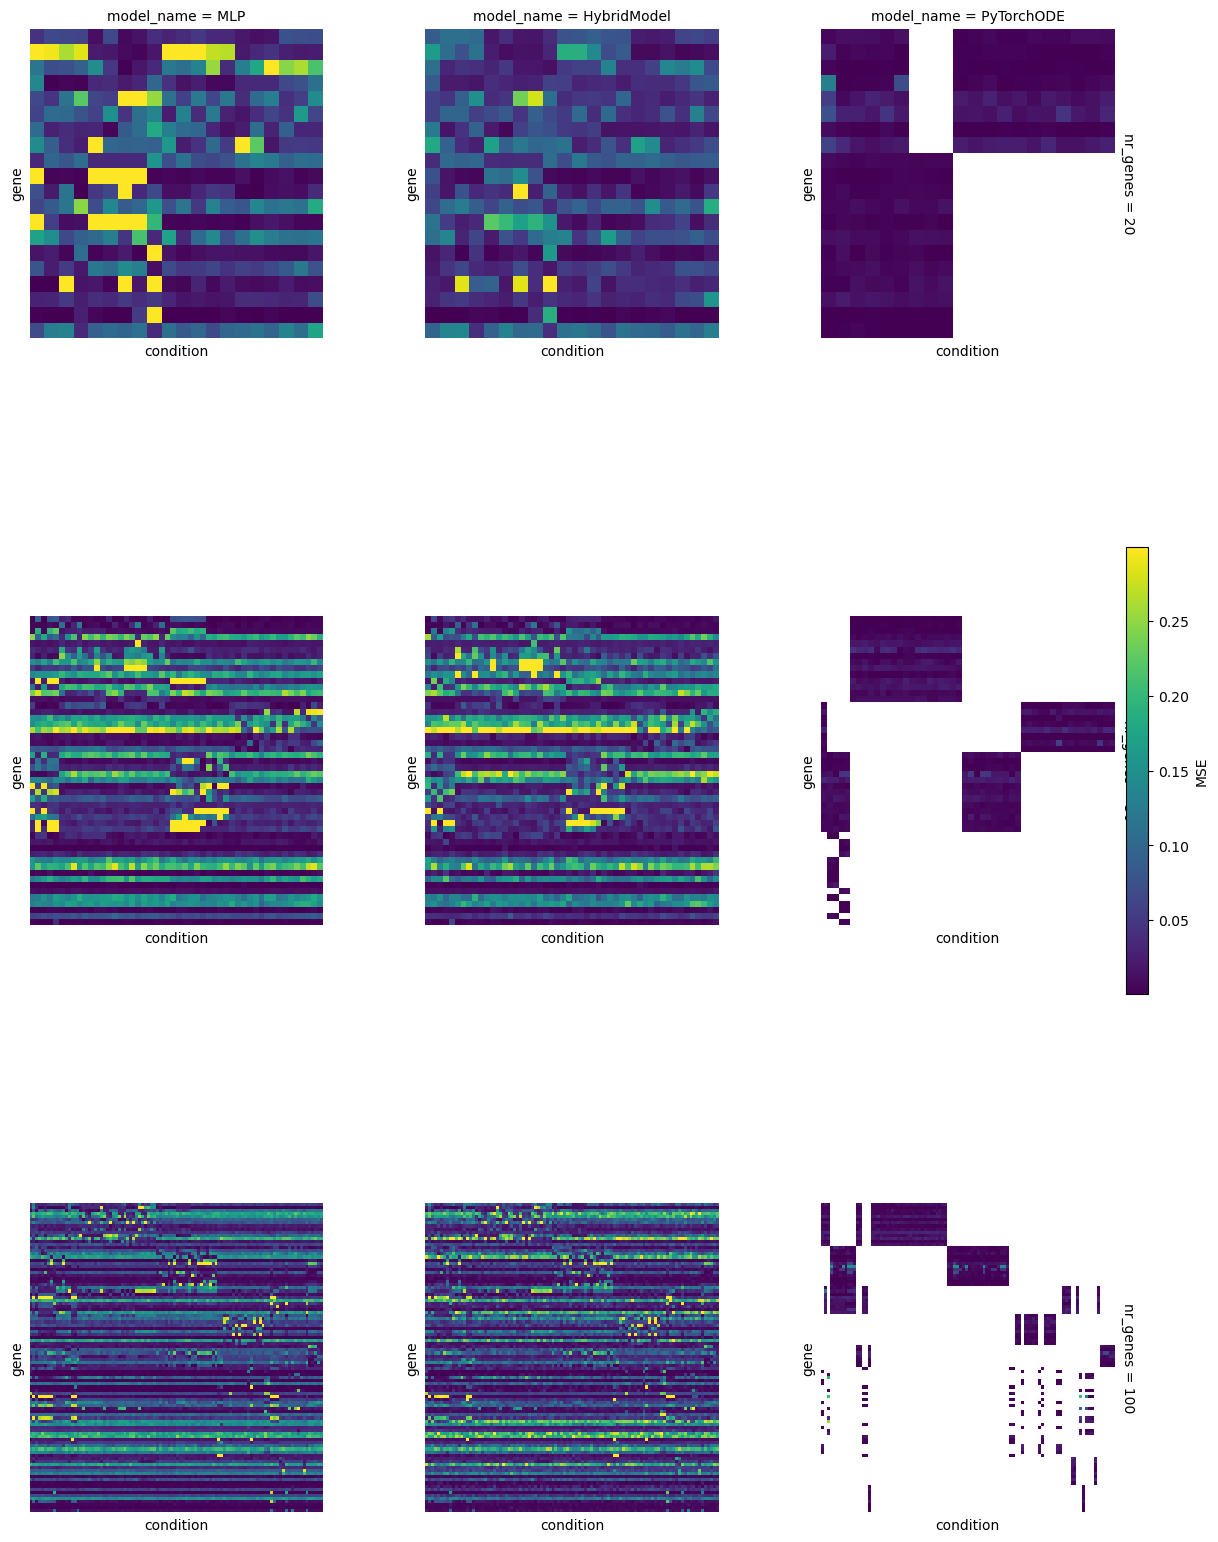

In [43]:
# Do the actual plotting
g = sns.FacetGrid(
    mse_df, col='model_name', row='nr_genes', margin_titles=True, aspect=.7, height=6, sharex=False, sharey=False, col_order=['MLP', 'HybridModel', 'PyTorchODE'],
)

def _plot_heatmap_func(data, **kwargs):
    nr_genes = data['gene'].nunique()
    gene_order = gene_order_dict[str(nr_genes)]
    cond_order = cond_order_dict[str(nr_genes)]
    df_pivot = data.pivot(
        index=DfColumnNames.GENE_COL,
        columns=DfColumnNames.CONDITION_COL,
        values=DfColumnNames.MSE_COL,
    ).reindex(index=gene_order, columns=cond_order) # , columns=col_order)
    sns.heatmap(data=df_pivot, cmap=cmap, norm=norm, cbar=False, **kwargs)

g.map_dataframe(_plot_heatmap_func)


# Remove all gene and condition names
for ax in g.axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

# add one shared colourbar
mappable = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
mappable.set_array([])
g.figure.colorbar(mappable, ax=g.axes, fraction=0.02, pad=0.01, label="MSE")
